# **PROJECT**


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('heart.csv')

In [4]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


# EDA


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


In [6]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [7]:
df.shape

(918, 12)

In [8]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')

In [9]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='HeartDisease'>

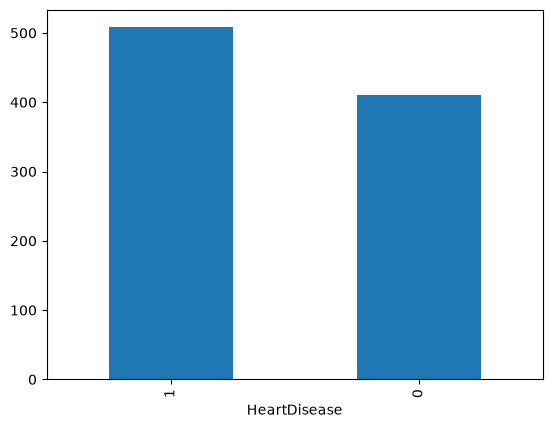

In [10]:
df['HeartDisease'].value_counts().plot(kind='bar')

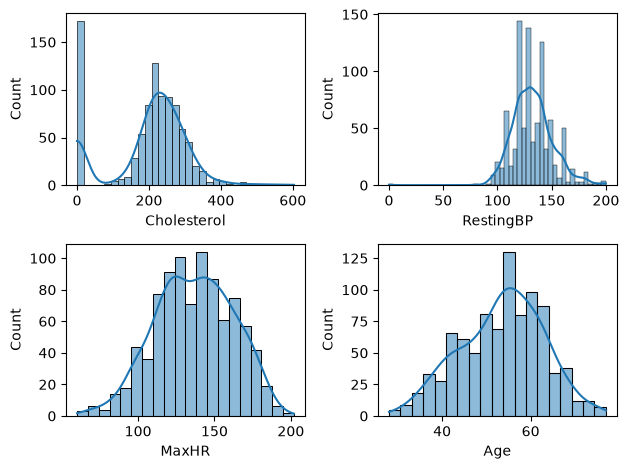

In [11]:
def plotting(col, num):
    plt.subplot(2,2,num)
    sns.histplot(df[col],kde=True)

plotting('Cholesterol',1)
plotting('RestingBP',2)
plotting('MaxHR',3)
plotting('Age',4)

plt.tight_layout()


In [12]:
df['Cholesterol'].value_counts()

Cholesterol
0      172
254     11
223     10
220     10
211      9
      ... 
353      1
278      1
157      1
176      1
131      1
Name: count, Length: 222, dtype: int64

In [13]:
ch_mean = df.loc[df['Cholesterol'] != 0, 'Cholesterol'].mean()
df['Cholesterol'] = df['Cholesterol'].replace(0,ch_mean)
df['Cholesterol'].value_counts()

Cholesterol
244.635389    172
254.000000     11
223.000000     10
220.000000     10
211.000000      9
             ... 
353.000000      1
278.000000      1
157.000000      1
176.000000      1
131.000000      1
Name: count, Length: 222, dtype: int64

In [14]:
ch_mean = df.loc[df['RestingBP'] != 0, 'RestingBP'].mean()
df['RestingBP'] = df['RestingBP'].replace(0,ch_mean)
df['RestingBP'].value_counts()

RestingBP
120.0    132
130.0    118
140.0    107
110.0     58
150.0     55
        ... 
174.0      1
117.0      1
192.0      1
129.0      1
164.0      1
Name: count, Length: 67, dtype: int64

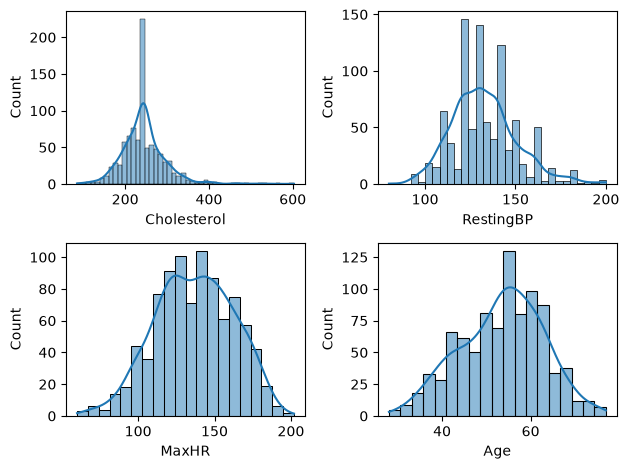

In [15]:
plotting('Cholesterol',1)
plotting('RestingBP',2)
plotting('MaxHR',3)
plotting('Age',4)

plt.tight_layout()

In [16]:
import sheryanalysis as sh
sh.analyze(df)


🔍 Basic Analysis Report
------------------------------------------------------------
📏 Shape: (918, 12)
🧱 Columns: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

✅ No null values found

🔠 Categorical Columns: ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'HeartDisease']

🔢 Numerical Columns: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']


{'shape': (918, 12),
 'columns': ['Age',
  'Sex',
  'ChestPainType',
  'RestingBP',
  'Cholesterol',
  'FastingBS',
  'RestingECG',
  'MaxHR',
  'ExerciseAngina',
  'Oldpeak',
  'ST_Slope',
  'HeartDisease'],
 'dtypes': {'Age': dtype('int64'),
  'Sex': <StringDtype(na_value=nan)>,
  'ChestPainType': <StringDtype(na_value=nan)>,
  'RestingBP': dtype('float64'),
  'Cholesterol': dtype('float64'),
  'FastingBS': dtype('int64'),
  'RestingECG': <StringDtype(na_value=nan)>,
  'MaxHR': dtype('int64'),
  'ExerciseAngina': <StringDtype(na_value=nan)>,
  'Oldpeak': dtype('float64'),
  'ST_Slope': <StringDtype(na_value=nan)>,
  'HeartDisease': dtype('int64')},
 'null_counts': {'Age': 0,
  'Sex': 0,
  'ChestPainType': 0,
  'RestingBP': 0,
  'Cholesterol': 0,
  'FastingBS': 0,
  'RestingECG': 0,
  'MaxHR': 0,
  'ExerciseAngina': 0,
  'Oldpeak': 0,
  'ST_Slope': 0,
  'HeartDisease': 0},
 'total_rows': 918,
 'column_types': {'categorical': ['Sex',
   'ChestPainType',
   'FastingBS',
   'RestingECG',

<Axes: xlabel='Sex', ylabel='count'>

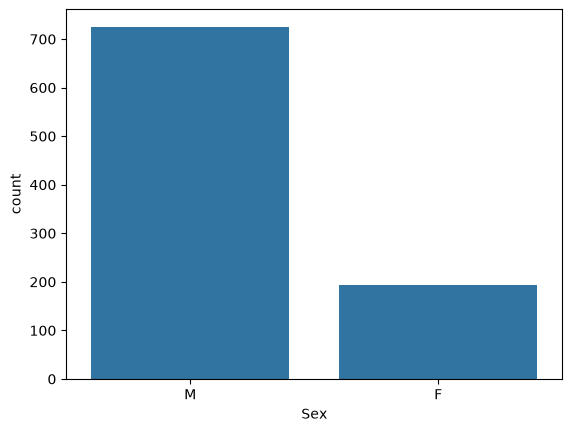

In [17]:
sns.countplot(x=df['Sex'])

<Axes: xlabel='ChestPainType', ylabel='count'>

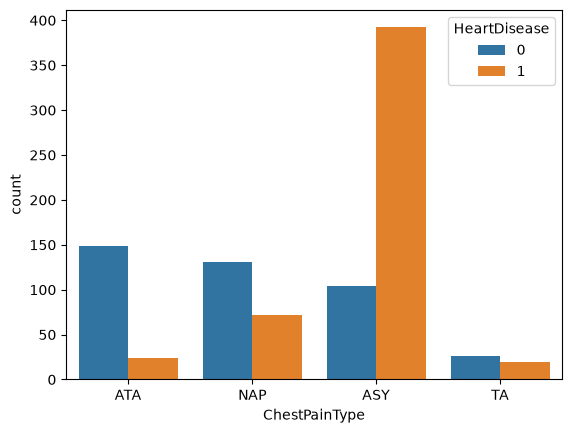

In [18]:
sns.countplot(x=df['ChestPainType'],hue=df['HeartDisease'])

<Axes: xlabel='FastingBS', ylabel='count'>

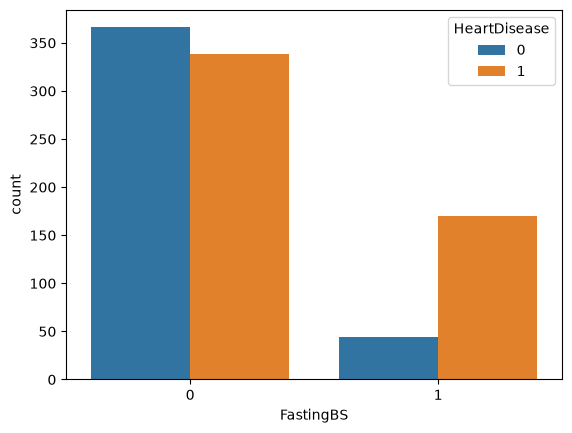

In [19]:
sns.countplot(x=df['FastingBS'],hue=df['HeartDisease'])

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

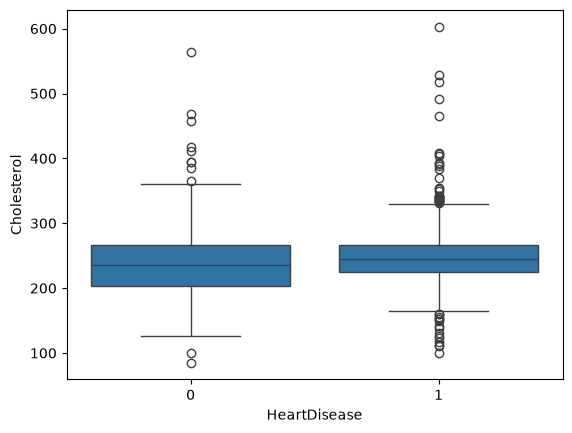

In [20]:
sns.boxplot(x=df['HeartDisease'],y=df['Cholesterol'])

<Axes: ylabel='Cholesterol'>

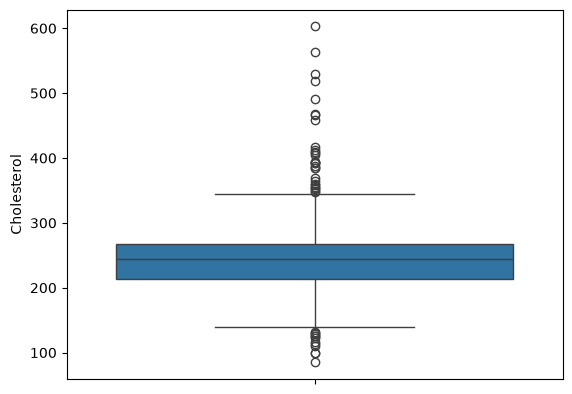

In [21]:
sns.boxplot(y='Cholesterol',data=df)

<Axes: xlabel='HeartDisease', ylabel='Age'>

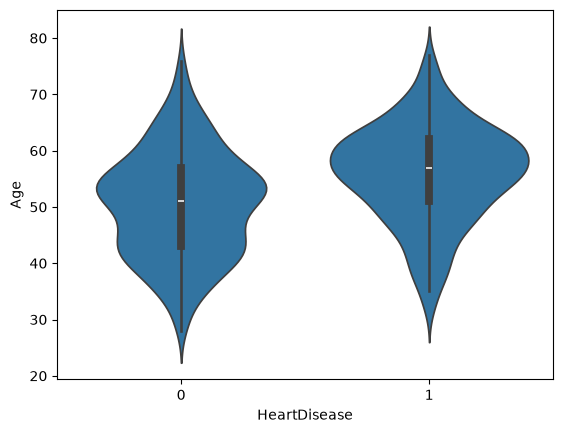

In [22]:
sns.violinplot(x='HeartDisease', y='Age', data=df)

<Axes: >

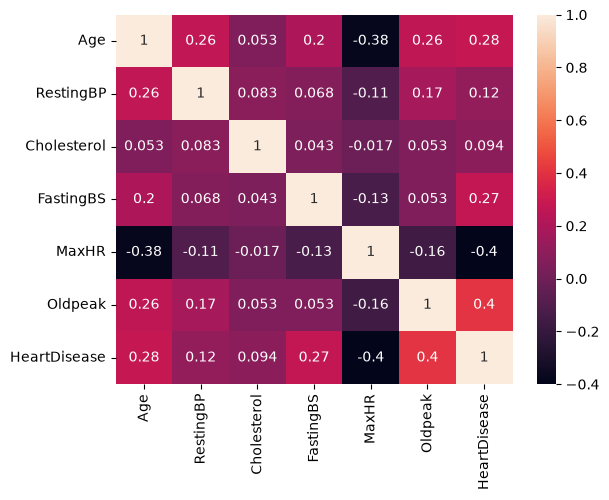

In [23]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

# FEATURE ENGINEERING


In [24]:
df['bp_level'] = pd.cut(
    df['RestingBP'],
    bins=[0,90,119,129,139,float('inf')],
    labels=['Low_blood_Pressure','Normal_systolic_BP','Elevated_systolic_BP','High_BP_Stage_1','High_BP_Stage_2']
)

In [25]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,bp_level
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0,High_BP_Stage_2
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1,High_BP_Stage_2
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0,High_BP_Stage_1
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1,High_BP_Stage_1
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0,High_BP_Stage_2


In [26]:
df['cholesterol_level'] = pd.cut(
    df['Cholesterol'],
    bins=[float('-inf'),200,239,float('inf')],
    labels=['Normal','Moderate','High']
)

In [27]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,bp_level,cholesterol_level
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0,High_BP_Stage_2,High
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1,High_BP_Stage_2,Normal
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0,High_BP_Stage_1,High
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1,High_BP_Stage_1,Moderate
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0,High_BP_Stage_2,Normal


In [28]:
df['HR_level'] = pd.cut(
    df['Cholesterol'],
    bins=[float('-inf'),100,139,float('inf')],
    labels=['Normal','Moderate','High']
)

In [29]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,bp_level,cholesterol_level,HR_level
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0,High_BP_Stage_2,High,High
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1,High_BP_Stage_2,Normal,High
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0,High_BP_Stage_1,High,High
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1,High_BP_Stage_1,Moderate,High
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0,High_BP_Stage_2,Normal,High


# DATA PREPROCESSING AND CLEANING


In [30]:
df_encode = pd.get_dummies(df,drop_first=True)

In [31]:
df_encode.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,bp_level_Normal_systolic_BP,bp_level_Elevated_systolic_BP,bp_level_High_BP_Stage_1,bp_level_High_BP_Stage_2,cholesterol_level_Moderate,cholesterol_level_High,HR_level_Moderate,HR_level_High
0,40,140.0,289.0,0,172,0.0,0,True,True,False,False,True,False,False,False,True,False,False,False,True,False,True,False,True
1,49,160.0,180.0,0,156,1.0,1,False,False,True,False,True,False,False,True,False,False,False,False,True,False,False,False,True
2,37,130.0,283.0,0,98,0.0,0,True,True,False,False,False,True,False,False,True,False,False,True,False,False,True,False,True
3,48,138.0,214.0,0,108,1.5,1,False,False,False,False,True,False,True,True,False,False,False,True,False,True,False,False,True
4,54,150.0,195.0,0,122,0.0,0,True,False,True,False,True,False,False,False,True,False,False,False,True,False,False,False,True


In [32]:
df_encode.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up',
       'bp_level_Normal_systolic_BP', 'bp_level_Elevated_systolic_BP',
       'bp_level_High_BP_Stage_1', 'bp_level_High_BP_Stage_2',
       'cholesterol_level_Moderate', 'cholesterol_level_High',
       'HR_level_Moderate', 'HR_level_High'],
      dtype='str')

In [33]:
df_encode[['Sex_M','ChestPainType_ATA','ChestPainType_NAP','ChestPainType_TA',
        'RestingECG_Normal','RestingECG_ST','ExerciseAngina_Y','ST_Slope_Flat',
        'ST_Slope_Up','bp_level_Normal_systolic_BP', 'bp_level_Elevated_systolic_BP',
       'bp_level_High_BP_Stage_1', 'bp_level_High_BP_Stage_2',
       'cholesterol_level_Moderate', 'cholesterol_level_High',
       'HR_level_Moderate', 'HR_level_High']] = df_encode[[
               
        'Sex_M','ChestPainType_ATA','ChestPainType_NAP','ChestPainType_TA',
        'RestingECG_Normal','RestingECG_ST','ExerciseAngina_Y','ST_Slope_Flat',
        'ST_Slope_Up','bp_level_Normal_systolic_BP', 'bp_level_Elevated_systolic_BP',
       'bp_level_High_BP_Stage_1', 'bp_level_High_BP_Stage_2',
       'cholesterol_level_Moderate', 'cholesterol_level_High',
       'HR_level_Moderate', 'HR_level_High']].astype('int')

In [34]:
df_encode.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,bp_level_Normal_systolic_BP,bp_level_Elevated_systolic_BP,bp_level_High_BP_Stage_1,bp_level_High_BP_Stage_2,cholesterol_level_Moderate,cholesterol_level_High,HR_level_Moderate,HR_level_High
0,40,140.0,289.0,0,172,0.0,0,1,1,0,0,1,0,0,0,1,0,0,0,1,0,1,0,1
1,49,160.0,180.0,0,156,1.0,1,0,0,1,0,1,0,0,1,0,0,0,0,1,0,0,0,1
2,37,130.0,283.0,0,98,0.0,0,1,1,0,0,0,1,0,0,1,0,0,1,0,0,1,0,1
3,48,138.0,214.0,0,108,1.5,1,0,0,0,0,1,0,1,1,0,0,0,1,0,1,0,0,1
4,54,150.0,195.0,0,122,0.0,0,1,0,1,0,1,0,0,0,1,0,0,0,1,0,0,0,1


In [35]:
from sklearn.preprocessing import StandardScaler

numerical_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
scaler = StandardScaler()
df_encode[numerical_cols] = scaler.fit_transform(df_encode[numerical_cols])
df_encode.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,bp_level_Normal_systolic_BP,bp_level_Elevated_systolic_BP,bp_level_High_BP_Stage_1,bp_level_High_BP_Stage_2,cholesterol_level_Moderate,cholesterol_level_High,HR_level_Moderate,HR_level_High
0,-1.433140,0.414853,0.832529,0,1.382928,-0.832432,0,1,1,0,0,1,0,0,0,1,0,0,0,1,0,1,0,1
1,-0.478484,1.527192,-1.212922,0,0.754157,0.105664,1,0,0,1,0,1,0,0,1,0,0,0,0,1,0,0,0,1
2,-1.751359,-0.141317,0.719935,0,-1.525138,-0.832432,0,1,1,0,0,0,1,0,0,1,0,0,1,0,0,1,0,1
3,-0.584556,0.303619,-0.574892,0,-1.132156,0.574711,1,0,0,0,0,1,0,1,1,0,0,0,1,0,1,0,0,1
4,0.051881,0.971022,-0.931438,0,-0.581981,-0.832432,0,1,0,1,0,1,0,0,0,1,0,0,0,1,0,0,0,1


# FEATURE SELECTION


In [36]:
import sheryanalysis as sh
sh.analyze(df_encode)


🔍 Basic Analysis Report
------------------------------------------------------------
📏 Shape: (918, 24)
🧱 Columns: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up', 'bp_level_Normal_systolic_BP', 'bp_level_Elevated_systolic_BP', 'bp_level_High_BP_Stage_1', 'bp_level_High_BP_Stage_2', 'cholesterol_level_Moderate', 'cholesterol_level_High', 'HR_level_Moderate', 'HR_level_High']

✅ No null values found

🔠 Categorical Columns: ['FastingBS', 'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up', 'bp_level_Normal_systolic_BP', 'bp_level_Elevated_systolic_BP', 'bp_level_High_BP_Stage_1', 'bp_level_High_BP_Stage_2', 'cholesterol_level_Moderate', 'cholesterol_level_High', 'HR_level


🔢 Numerical Columns: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']


{'shape': (918, 24),
 'columns': ['Age',
  'RestingBP',
  'Cholesterol',
  'FastingBS',
  'MaxHR',
  'Oldpeak',
  'HeartDisease',
  'Sex_M',
  'ChestPainType_ATA',
  'ChestPainType_NAP',
  'ChestPainType_TA',
  'RestingECG_Normal',
  'RestingECG_ST',
  'ExerciseAngina_Y',
  'ST_Slope_Flat',
  'ST_Slope_Up',
  'bp_level_Normal_systolic_BP',
  'bp_level_Elevated_systolic_BP',
  'bp_level_High_BP_Stage_1',
  'bp_level_High_BP_Stage_2',
  'cholesterol_level_Moderate',
  'cholesterol_level_High',
  'HR_level_Moderate',
  'HR_level_High'],
 'dtypes': {'Age': dtype('float64'),
  'RestingBP': dtype('float64'),
  'Cholesterol': dtype('float64'),
  'FastingBS': dtype('int64'),
  'MaxHR': dtype('float64'),
  'Oldpeak': dtype('float64'),
  'HeartDisease': dtype('int64'),
  'Sex_M': dtype('int64'),
  'ChestPainType_ATA': dtype('int64'),
  'ChestPainType_NAP': dtype('int64'),
  'ChestPainType_TA': dtype('int64'),
  'RestingECG_Normal': dtype('int64'),
  'RestingECG_ST': dtype('int64'),
  'ExerciseAn

In [37]:
df_encode.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up',
       'bp_level_Normal_systolic_BP', 'bp_level_Elevated_systolic_BP',
       'bp_level_High_BP_Stage_1', 'bp_level_High_BP_Stage_2',
       'cholesterol_level_Moderate', 'cholesterol_level_High',
       'HR_level_Moderate', 'HR_level_High'],
      dtype='str')

In [38]:
from scipy.stats import f_oneway
selected_features =  ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
test_result = {}
alpha = 0.05

for col in selected_features:
    group0 = df_encode[df_encode['HeartDisease'] == 0][col].dropna()
    group1 = df_encode[df_encode['HeartDisease'] == 1][col].dropna()
    f_stat, p_value = f_oneway(group0, group1)
    decision = 'Reject Null (keep Feature)' if p_value < alpha else 'Accept Null (Drop Feature)'
    test_result[col] = {
        "f_stat" : f_stat,
        'p_value' : p_value,
        'decision':decision
    }
chi2_df = pd.DataFrame(test_result).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,f_stat,p_value,decision
Oldpeak,178.61512,0.0,Reject Null (keep Feature)
MaxHR,174.913585,0.0,Reject Null (keep Feature)
Age,79.160779,0.0,Reject Null (keep Feature)
RestingBP,12.920719,0.000342,Reject Null (keep Feature)
Cholesterol,8.178434,0.004335,Reject Null (keep Feature)


In [39]:
from scipy.stats import chi2_contingency

alpha=0.05
selected_cat_features = ['FastingBS', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up', 'bp_level_Normal_systolic_BP', 'bp_level_Elevated_systolic_BP', 'bp_level_High_BP_Stage_1', 'bp_level_High_BP_Stage_2', 'cholesterol_level_Moderate', 'cholesterol_level_High', 'HR_level_Moderate', 'HR_level_High']
chi2_results = {}

for col in selected_cat_features:
    contingency = pd.crosstab(df_encode[col], df_encode['HeartDisease'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    chi2_results[col] = {
        'chi2_statistic' : chi2_stat,
        'p_value' : p_val,
        'Decision' : decision
    }

chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi2_statistic,p_value,Decision
ST_Slope_Up,352.823905,0.0,Reject Null (keep Feature)
ST_Slope_Flat,279.659914,0.0,Reject Null (keep Feature)
ExerciseAngina_Y,222.259383,0.0,Reject Null (keep Feature)
ChestPainType_ATA,146.236323,0.0,Reject Null (keep Feature)
Sex_M,84.145101,0.0,Reject Null (keep Feature)
FastingBS,64.320679,0.0,Reject Null (keep Feature)
ChestPainType_NAP,40.608711,0.0,Reject Null (keep Feature)
cholesterol_level_High,39.09985,0.0,Reject Null (keep Feature)
cholesterol_level_Moderate,11.715385,0.00062,Reject Null (keep Feature)
bp_level_High_BP_Stage_2,10.655415,0.001097,Reject Null (keep Feature)


In [40]:
final_df = df_encode.drop(columns=['bp_level_Elevated_systolic_BP','ChestPainType_TA','bp_level_High_BP_Stage_1','HR_level_Moderate','bp_level_Normal_systolic_BP','HR_level_High'])

In [41]:
final_df.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,bp_level_High_BP_Stage_2,cholesterol_level_Moderate,cholesterol_level_High
0,-1.433140,0.414853,0.832529,0,1.382928,-0.832432,0,1,1,0,1,0,0,0,1,1,0,1
1,-0.478484,1.527192,-1.212922,0,0.754157,0.105664,1,0,0,1,1,0,0,1,0,1,0,0
2,-1.751359,-0.141317,0.719935,0,-1.525138,-0.832432,0,1,1,0,0,1,0,0,1,0,0,1
3,-0.584556,0.303619,-0.574892,0,-1.132156,0.574711,1,0,0,0,1,0,1,1,0,0,1,0
4,0.051881,0.971022,-0.931438,0,-0.581981,-0.832432,0,1,0,1,1,0,0,0,1,1,0,0
